# 3. CNN with EEI at one angle: χ = −60°

EEI(−60°) is the angle most sensitive to Vs at Well 2X (manuscript Figure 4).

This is one of the tests of manuscript Table 5. The regression network is trained **with the
same settings, the same seed (0) and the same pseudo-wells** as in notebook 02; only the EEI
angles of the input change. The EEI of the pseudo-wells is recomputed at the new angles
(`CNN_libs/eei_angles.py`); the properties and facies are those of `training_data/`. Only the
regression network is trained.

**Run time:** about 30 minutes on one NVIDIA H100 GPU.

**Outputs:** `Notebooks/outputs/CNN/training_data_chi_m60/` and `Notebooks/outputs/CNN/ablation_chi_m60/`.

In [1]:
%matplotlib inline
import json, shutil, time
import numpy as np
from IPython.display import Markdown, display
from nb_utils import *

environment()

NAME = "chi_m60"
CHIS = [-60.0]
TD = CNN_OUT / f"training_data_{NAME}"
RUN = CNN_OUT / f"ablation_{NAME}"
print("EEI angles:", ", ".join(f"{c:g}°" for c in CHIS))

Python 3.12.0, numpy 2.2.6


PyTorch 2.8.0+cu128, GPU: NVIDIA H100 80GB HBM3
CPU cores: 16
Package root: Stochastic_Inv_Code_Release/
Well 9P logs: not distributed (blind-well comparison skipped)
EEI angles: -60°


## Training set at the new angles

The 100,000 pseudo-wells of notebook 02 are used. If they do not exist yet, they are generated
here with the same seed, which gives the same pseudo-wells.

$ python CNN_libs/eei_angles.py --train-dir Notebooks/outputs/CNN/training_data --outdir Notebooks/outputs/CNN/training_data_chi_m60 --chis -60.0


  100000 pseudo-wells x 1 angles x 184 ms -> Notebooks/outputs/CNN/training_data_chi_m60/
[3 s, full log: Notebooks/outputs/CNN/ablation_chi_m60/import.log]


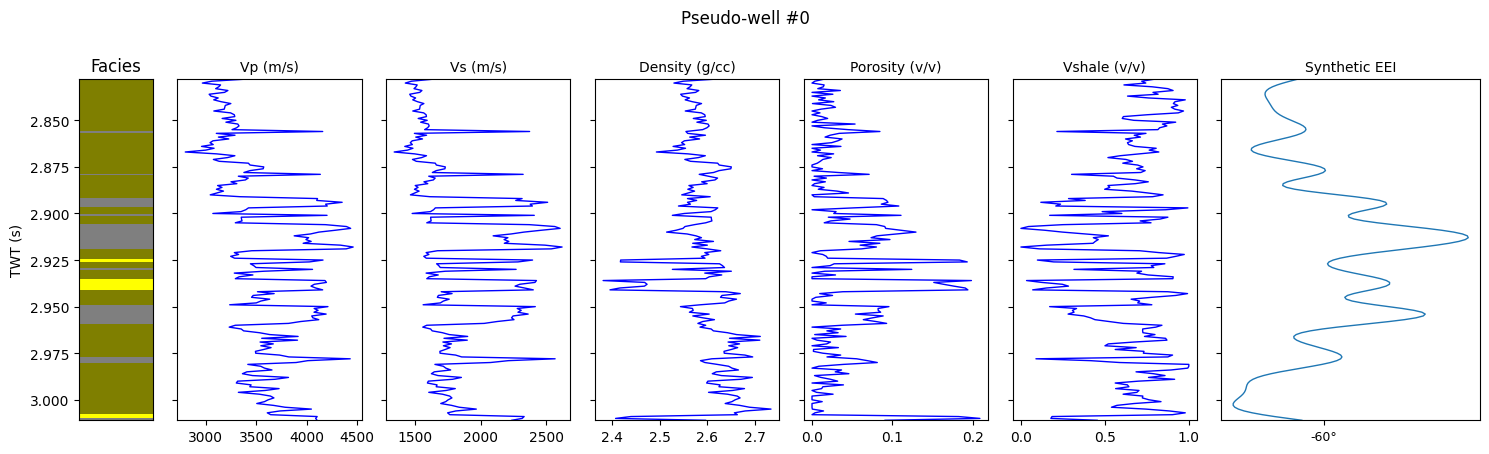

Facies fractions over the training set: shale 71.7%, silt 11.4%, sand 14.4%, calcareous sand 2.5%


In [2]:
if not (TRAIN_DIR / "eei.npy").exists():
    run("make_datamat.py", "--outdir", TRAIN_DIR, "--n", "100000", "--format", "npy",
        log=CNN_OUT / "training_data.log")
if not (TD / "eei.npy").exists():
    run("eei_angles.py", "--train-dir", TRAIN_DIR, "--outdir", TD, "--chis", *CHIS, log=RUN / "import.log")
plot_pseudowells(TD, idx=(0,))

## Field data at these angles

In [3]:
plot_field_eei(CHIS)

## Regression network

In [4]:
if not (RUN / "model.pt").exists():
    run("train_cnn.py", "--train-dir", TD, "--outdir", RUN, "--seed", 0, *REG_ARGS, log=RUN / "train.log", tail=10)
else:
    print("network exists:", RUN.relative_to(ROOT))
plot_history(RUN, title=f"Regression CNN, EEI at {len(CHIS)} angle(s)")

$ python CNN_libs/train_cnn.py --train-dir Notebooks/outputs/CNN/training_data_chi_m60 --outdir Notebooks/outputs/CNN/ablation_chi_m60 --seed 0 --arch keras --epochs 150 --batch 32 --lr 1e-3 --weight-decay 0 --dropout 0.3 --reg-loss mse --cls-weight 0 --calibration none --gain-jitter 0 --mc-test 0


  ...
  epoch 148  train 0.5172 (reg 0.5172, CE 1.3863)  val 0.4504 (reg 0.4504, CE 1.3863)  2434 s
  epoch 149  train 0.5171 (reg 0.5171, CE 1.3863)  val 0.4506 (reg 0.4506, CE 1.3863)  2451 s
  epoch 150  train 0.5174 (reg 0.5174, CE 1.3863)  val 0.4502 (reg 0.4502, CE 1.3863)  2467 s
  median correlation per pseudo-well         vp      vs     rho    poro  vshale
  train                0.793   0.796   0.705   0.701   0.732   facies acc 0.717, macro-F1 0.209
  test                 0.794   0.796   0.703   0.697   0.729   facies acc 0.718, macro-F1 0.209
  test_noise_free      0.794   0.796   0.703   0.697   0.729   facies acc 0.718, macro-F1 0.209
  coverage of 50%/90% intervals, test: vp 0.00/0.00, vs 0.00/0.00, rho 0.00/0.00, poro 0.00/0.00, vshale 0.00/0.00
  coverage of 50%/90% intervals, test_noise_free: vp 0.00/0.00, vs 0.00/0.00, rho 0.00/0.00, poro 0.00/0.00, vshale 0.00/0.00
  saved model and QC figures to Notebooks/outputs/CNN/ablation_chi_m60/ (training 2467 s)
[2482 s, full

Median correlation on the 10,000 test pseudo-wells, compared with the four-angle network of notebook 02:

In [5]:
rows = {f"{NAME}": test_correlations(RUN)}
if (CNN_OUT / "regression_s0" / "metrics.json").exists():
    rows["four angles (notebook 02)"] = test_correlations(CNN_OUT / "regression_s0")
for r in rows.values():
    r["mean"] = float(np.mean([r[p] for p in PROPS]))
table(rows, list(PROPS) + ["mean"], index_name="test pseudo-wells")

| test pseudo-wells | vp | vs | rho | poro | vshale | mean |
|---|---|---|---|---|---|---|
| chi_m60 | 0.794 | 0.796 | 0.703 | 0.697 | 0.729 | 0.744 |
| four angles (notebook 02) | 0.835 | 0.839 | 0.817 | 0.796 | 0.768 | 0.811 |

## Application to the field line (100 MC Dropout passes)

$ python CNN_libs/infer_cnn.py --run Notebooks/outputs/CNN/ablation_chi_m60 --field-mode stretch --mc 100 --tag chi_m60 --outdir Notebooks/outputs/CNN/ablation_chi_m60/field


  ...
  inference: 100 MC-dropout passes in 0.44 s (input preparation 0.1 s)
  wrote SEG-Y and cnn_chi_m60.npz to Notebooks/outputs/CNN/ablation_chi_m60/field/
  wrote sections_chi_m60.png
[7 s, full log: Notebooks/outputs/CNN/ablation_chi_m60/infer.log]
$ python ODiSI_libs/make_paper_figures.py --input-dir Notebooks/outputs/CNN/ablation_chi_m60/field --tag chi_m60 --run-name chi_m60 --outdir Notebooks/outputs/CNN/ablation_chi_m60/figures --formats png --dpi 120


  ...
    Data/well9p_data.mat not found — Figure 3 shows the inversion only, no well logs or correlations
    wrote Well_9p_elasto_petrophysics_chi_m60.png
[4 s, full log: Notebooks/outputs/CNN/ablation_chi_m60/figures.log]


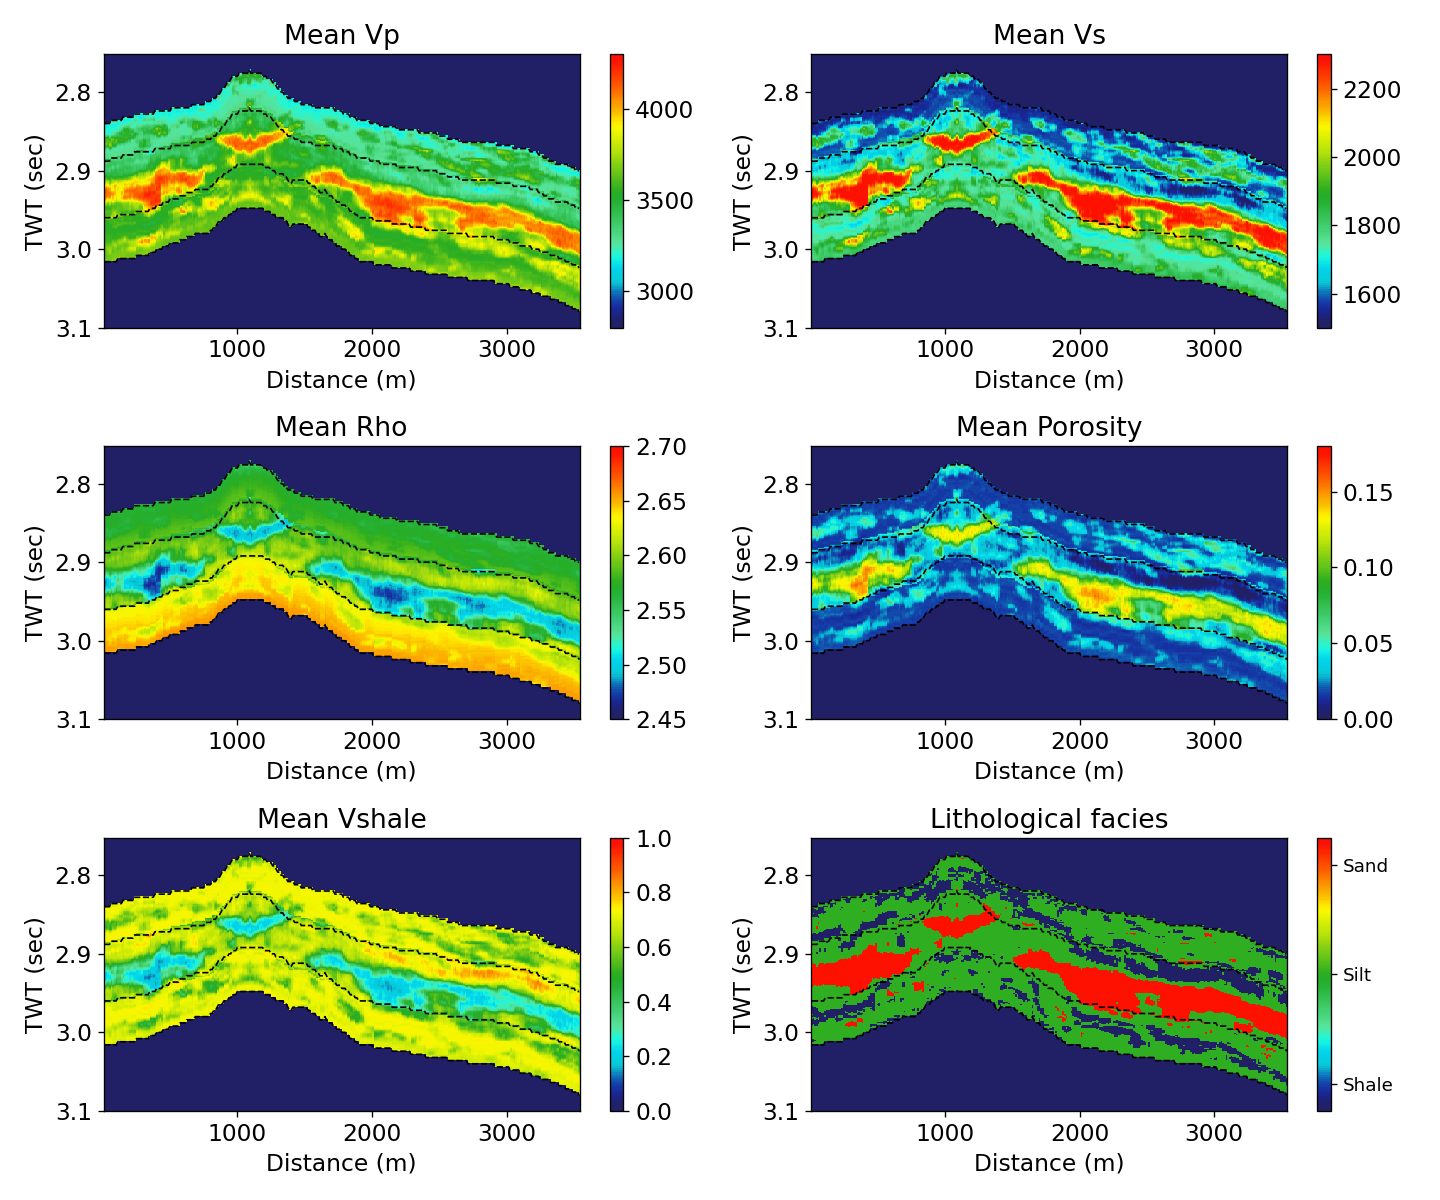

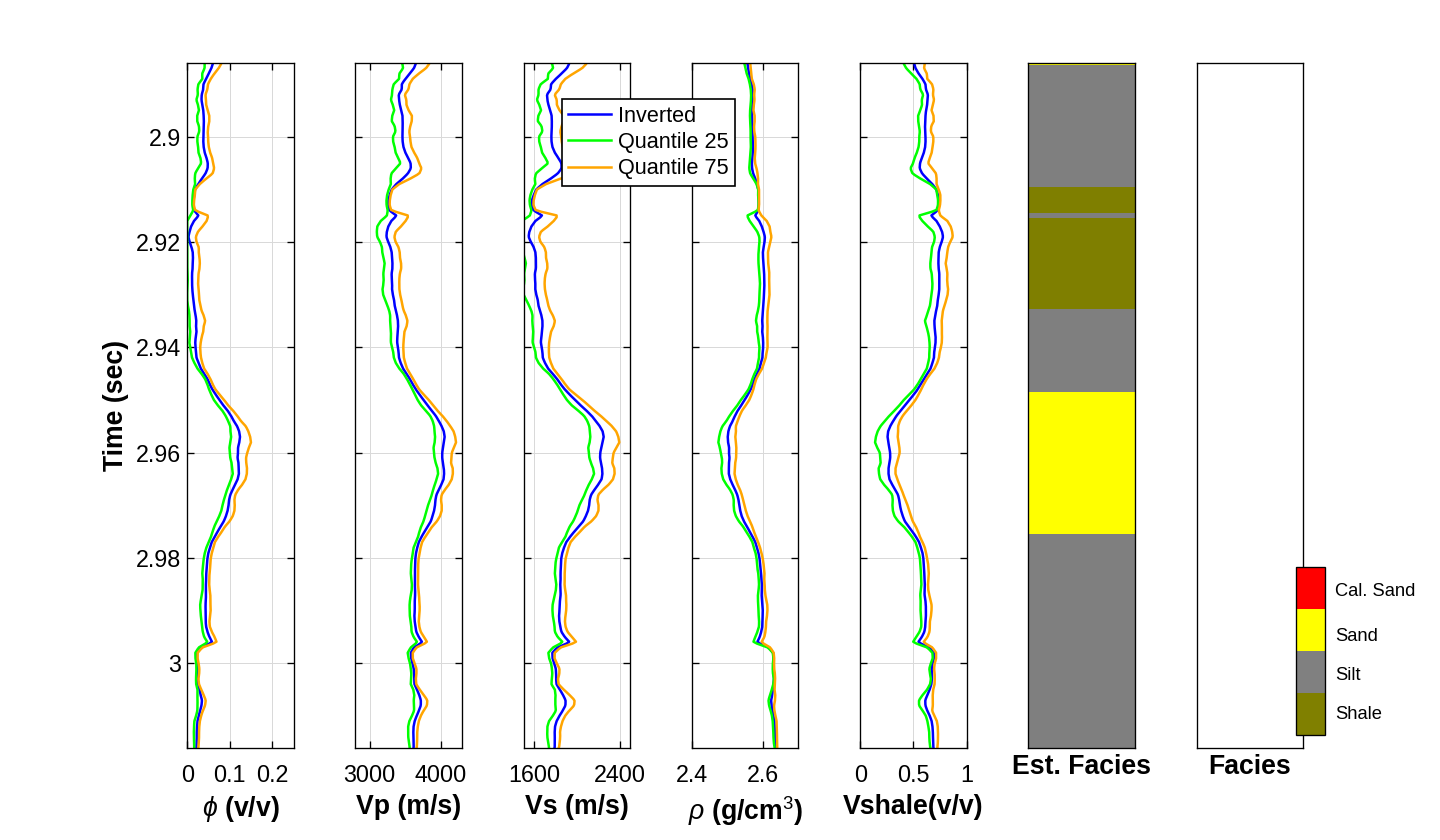

In [6]:
run("infer_cnn.py", "--run", RUN, "--field-mode", "stretch", "--mc", "100", "--tag", NAME,
    "--outdir", RUN / "field", log=RUN / "infer.log", tail=3)
run("make_paper_figures.py", "--input-dir", RUN / "field", "--tag", NAME, "--run-name", NAME,
    "--outdir", RUN / "figures", "--formats", "png", "--dpi", "120", log=RUN / "figures.log", tail=2)
show(first(RUN / "figures", "Stochastic_inversion_*.png"))
show(first(RUN / "figures", "Well_9p_elasto_petrophysics_*.png"), width=900)

## Blind well

Correlation coefficients at Well 9P in the manuscript (Table 5):

| EEI angles | Vp | Vs | ρ | Vshale | φ | mean |
|---|---|---|---|---|---|---|
| this test | 0.689 | 0.771 | 0.611 | 0.709 | 0.672 | 0.690 |
| four angles | 0.699 | 0.780 | 0.704 | 0.731 | 0.674 | 0.718 |

In [7]:
r = read_well_correlation(RUN / "figures" / f"well_correlation_{NAME}.txt")
if r:
    table({NAME: r}, list(PROPS))
else:
    print("Well 9P logs not available: blind-well correlations not computed.")

Well 9P logs not available: blind-well correlations not computed.
